# COUNTER: Connect Four con Minimax, Alpha-Beta y Expectimax

Este notebook muestra al **agente final** jugando, y las figuras y los resultados registrados en `results/`. Las partidas de los experimentos no se vuelven a jugar acá: se hacen con `experiments.py` (sección 5). Cada decisión está explicada en `../docs/DECISIONES.md`, y se cita como D-XX.

**Regla de captura** de esta versión (`board.py`): si una ficha rival queda encerrada entre dos propias en horizontal o en diagonal, pasa a ser propia. Con esta regla, el que empieza tiene victoria forzada desde el tablero vacío (D-32). Por eso los resultados siempre separan si nuestro agente juega primero o segundo.

**Agente final** (D-33, D-34): Minimax con poda Alpha-Beta, profundidad 5 y heurística `completa`, con las columnas centrales primero. Es determinista y no se entrena, así que no tiene un modelo `.pkl`.

Para jugar a mano contra el agente, poner `JUGAR_A_MANO = True` en la celda siguiente.

In [1]:
import csv
import time

from IPython.display import Image, Markdown, display

import plots  # figuras del informe: leen results/ y guardan en figures/
from agent import InputAgent
from connect_four_env import ConnectFourBaseEnv
from experiment_log import RESULTS_DIR
from heuristics import HEURISTICS
from match import StrategoAdapter
from minimax_agent import MinimaxAgent
from random_agent import RandomAgent

JUGAR_A_MANO = False  # True: partida por consola contra el agente (pide las jugadas con input)

print("Heurística completa, pesos:", HEURISTICS["completa"])

Heurística completa, pesos: {'n2': 2, 'n3': 5, 'centro': 3, 'amenazas': 20, 'capturas': 4}


## 1. El agente final contra Stratego

`Stratego` es el rival de la cátedra: un Minimax de profundidad 4. Se construye como en `play.py`, con `Stratego(2, 4)` (D-29). La partida arranca desde el tablero vacío. `O` es el jugador 1 y `X` el jugador 2.

**Ojo:** `Stratego(n, d)` se cree el jugador (n % 2) + 1, así que `Stratego(2, 4)` se cree el jugador 1. Cuando le toca jugar segundo, evalúa el tablero desde el lado equivocado y juega mucho peor (D-29). Por eso, cuando nuestro agente empieza, la partida dura pocas jugadas. La prueba exigente es la otra: nuestro agente juega segundo y Stratego juega en su turno fuerte. Ahí, sobre las 24 aperturas abiertas, gana 21 (C2).

Las fichas pueden cambiar de color por la regla de captura, así que puede haber más fichas de un jugador que jugadas hizo.

In [2]:
def partida(agentes):
    """Juega una partida desde el tablero vacío, muestra el tablero final y devuelve
    el ganador y los tiempos por jugada de cada jugador."""
    env = ConnectFourBaseEnv(render_mode="human")
    obs, _ = env.reset()
    turno, done, tiempos = 1, False, {1: [], 2: []}
    while not done:
        inicio = time.perf_counter()
        accion = agentes[turno].next_action(obs)
        tiempos[turno].append(time.perf_counter() - inicio)
        obs, _, done, _, _ = env.step(accion)
        turno = 2 if turno == 1 else 1
    env.render()
    return obs.winner, tiempos


for nuestro in (1, 2):
    rival = 2 if nuestro == 1 else 1
    agentes = {nuestro: MinimaxAgent(nuestro, depth=5, heuristic="completa"),
               rival: StrategoAdapter(rival, arg=2, depth=4)}
    ganador, tiempos = partida(agentes)
    resultado = "gana nuestro agente" if ganador == nuestro else ("empate" if ganador == 0 else "gana Stratego")
    t = tiempos[nuestro]
    print(f"Nuestro agente juega {'primero' if nuestro == 1 else 'segundo'}: {resultado}. "
          f"{len(t)} jugadas nuestras, {1000 * sum(t) / len(t):.0f} ms de media y {1000 * max(t):.0f} ms la más lenta.\n")

   0   1   2   3   4   5   6  
 |   |   |   |   |   |   |   |
 |   |   |   |   |   |   |   |
 |   |   |   |   |   |   |   |
 |   |   |   |   |   |   |   |
 |   |   |   |   |   |   |   |
 | X |   | O | O | O | O |   |
-------------------------------
Nuestro agente juega primero: gana nuestro agente. 3 jugadas nuestras, 80 ms de media y 106 ms la más lenta.

   0   1   2   3   4   5   6  
 |   |   |   |   |   |   |   |
 |   |   |   |   |   |   |   |
 |   |   |   |   |   |   | X |
 |   |   |   | O |   |   | O |
 |   |   |   | O |   |   | O |
 |   | X | X | X | X |   | O |
-------------------------------
Nuestro agente juega segundo: gana nuestro agente. 5 jugadas nuestras, 88 ms de media y 208 ms la más lenta.



## 2. Contra un rival al azar

In [3]:
ganador, tiempos = partida({1: MinimaxAgent(1), 2: RandomAgent(2, seed=0)})
print("Gana nuestro agente." if ganador == 1 else f"Ganador: {ganador}")

   0   1   2   3   4   5   6  
 |   |   |   |   |   |   |   |
 |   |   |   |   |   |   |   |
 |   |   |   |   |   |   |   |
 |   |   |   |   |   |   |   |
 |   |   |   | X |   |   | X |
 |   | O | O | O | O |   | X |
-------------------------------
Gana nuestro agente.


## 3. Figuras

`plots.py` genera las figuras desde los resúmenes que escribe `experiments.py` en `results/` (D-39).

In [4]:
for name, make_figure in plots.FIGURES.items():
    print(name)
    make_figure()

C1
  figures\C1_poda.png
C2
  figures\C2_minimax_vs_expectimax.png
C3
  figures\C3_heuristicas.png
C4
  figures\C4_profundidad.png


### C1. Impacto de la poda Alpha-Beta

En escala logarítmica, el crecimiento b^d se ve como una recta de pendiente b. La poda baja esa pendiente: el factor de ramificación efectivo pasa de 6.4 a 3.6 con el centro primero (98.4 % menos nodos con d = 7), y a 4.1 si se ordena de izquierda a derecha. **El orden importa:** probar primero las mejores jugadas produce cortes antes. La poda no cambia la decisión: se elige la misma jugada que sin poda en 350 de 350 búsquedas (D-27, D-30). Con el mismo tiempo, la poda permite unos 2 niveles más de profundidad.

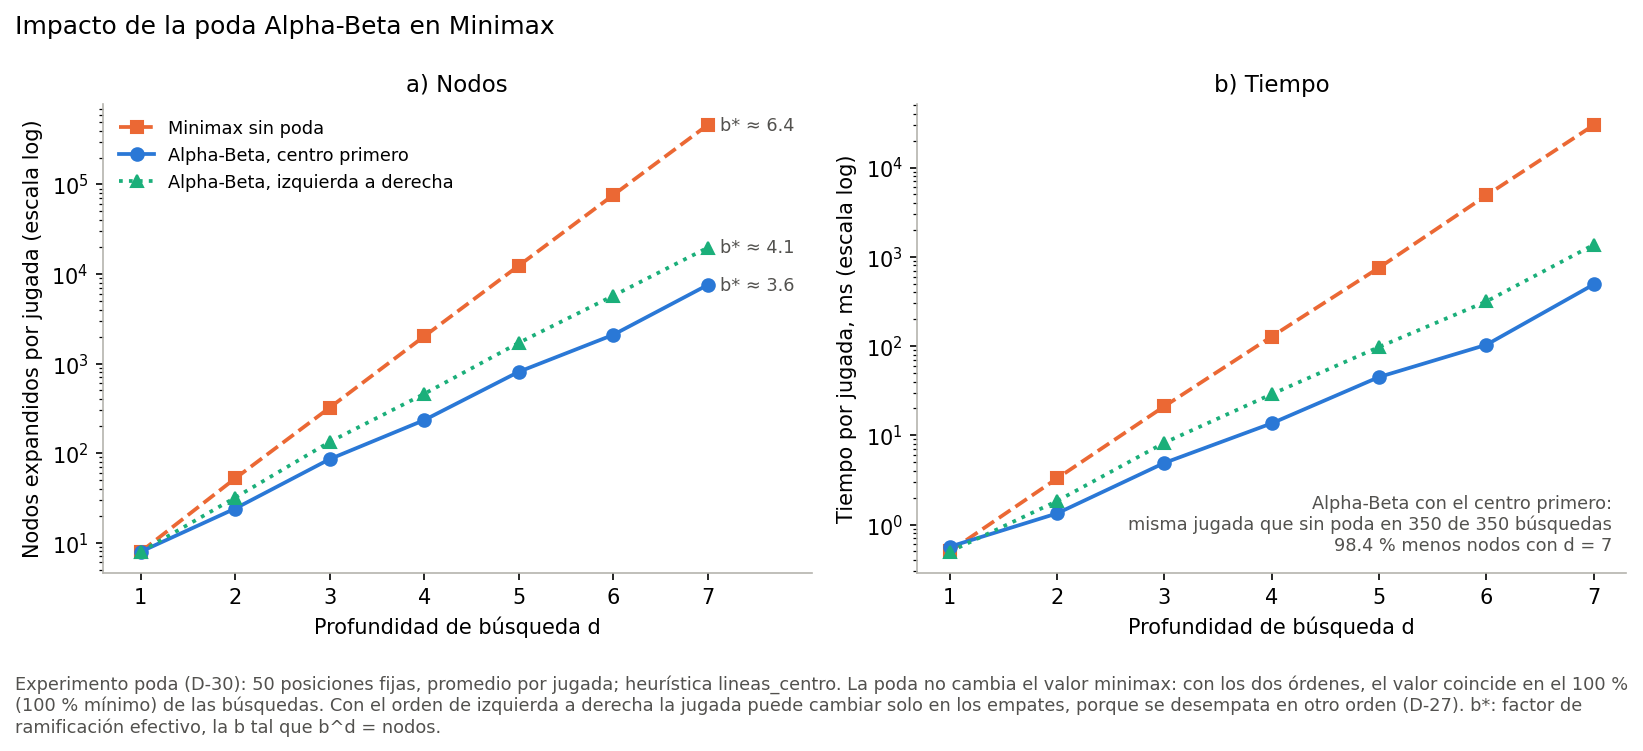

In [5]:
display(Image(filename="figures/C1_poda.png"))

### C2. Minimax contra Expectimax

Expectimax modela al rival como aleatorio (promedia sus jugadas), y Minimax como óptimo (supone su mejor respuesta). **Contra Random ganan todos**, y Expectimax gana un poco más rápido. **Contra Stratego, Minimax es claramente mejor:** jugando segundo gana 26 de 49 (21 de las 24 aperturas abiertas), contra 15 y 11 de Expectimax. Stratego no juega al azar y castiga las jugadas que Expectimax considera buenas "en promedio". Además, Expectimax no se puede podar, y a la misma profundidad es unas 10 veces más caro (D-34). Por eso el agente final es Minimax con Alpha-Beta.

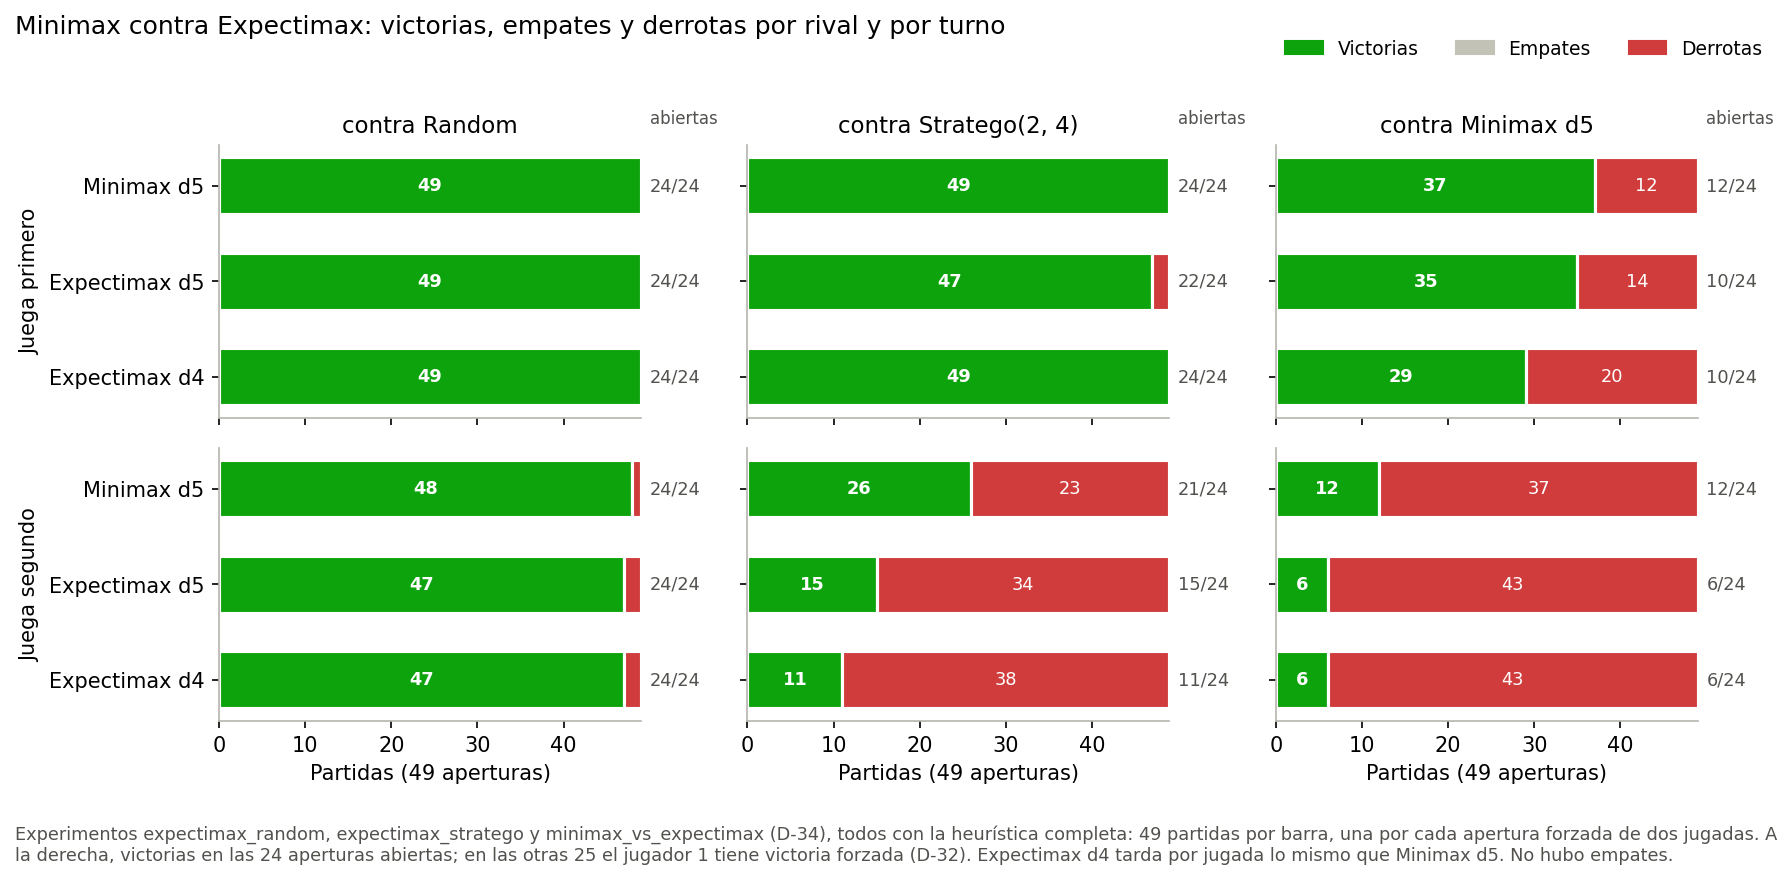

In [6]:
display(Image(filename="figures/C2_minimax_vs_expectimax.png"))

### C3. Funciones de evaluación

Jugando primero, todas las heurísticas ganan (con la regla de captura, el jugador 1 tiene ventaja). Solo se distinguen jugando segundo, en las aperturas abiertas. `completa` (líneas de 2 y 3, centro, amenazas y capturas) gana 20 de 24, contra 15 de la heurística nula. Lo que más suma son las **amenazas** y las **capturas**, porque reflejan la regla especial del juego. Las variaciones de los pesos casi no cambian el resultado (D-28, D-31).

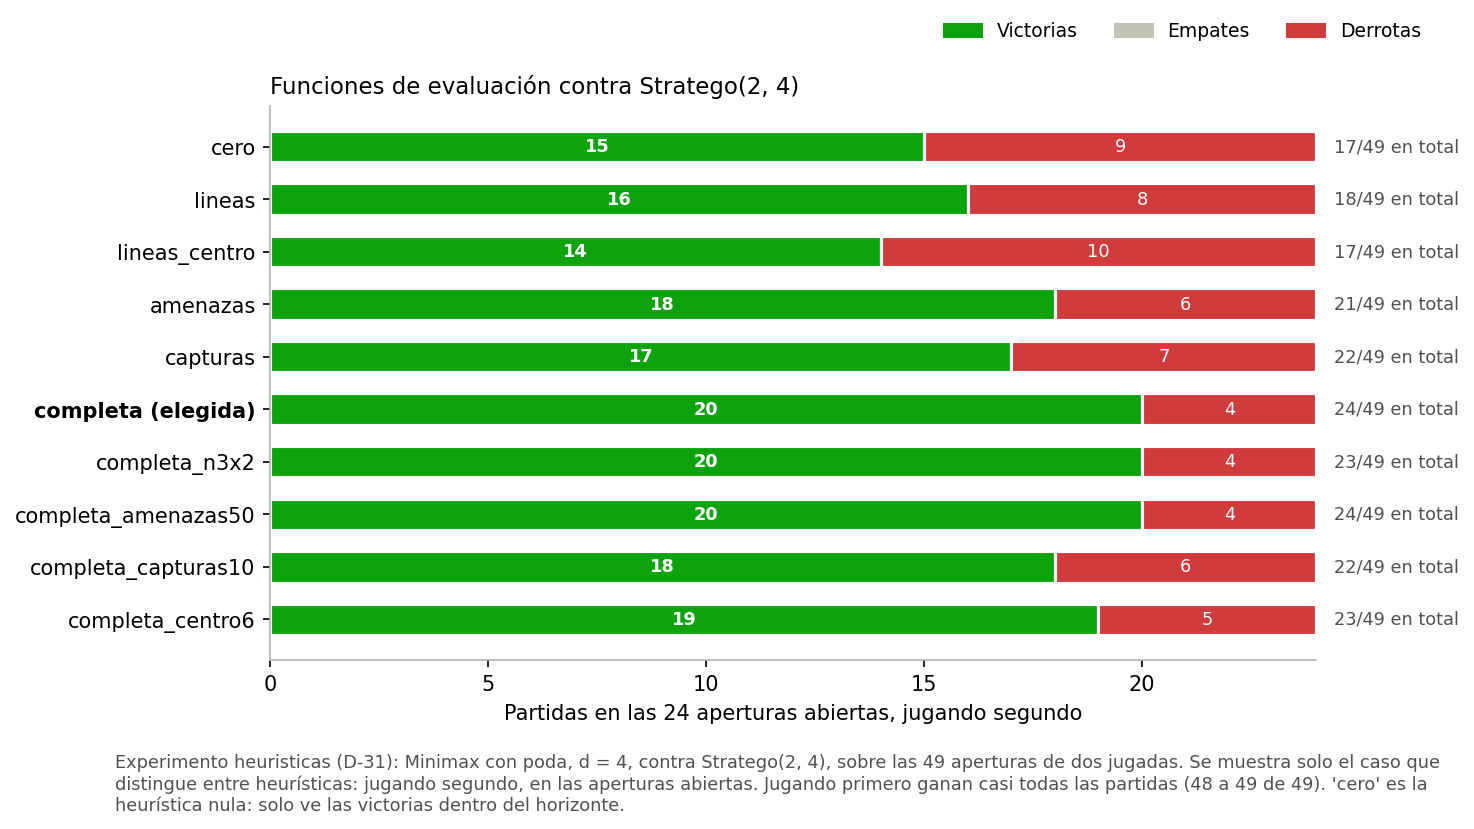

In [7]:
display(Image(filename="figures/C3_heuristicas.png"))

### C4. Profundidad contra rendimiento y costo

Jugando segundo, el rendimiento sube hasta d = 4 o 5 y después se estanca, mientras el tiempo crece exponencialmente. **d = 8 rinde peor que d = 7:** cuando Minimax ve una derrota forzada contra un rival óptimo, todas las jugadas valen lo mismo (−∞) y elige cualquiera, en vez de estirar la partida esperando un error de Stratego (D-33). Se eligió **d = 5**: unos 0.1 s por jugada en promedio y 0.8 s la más lenta.

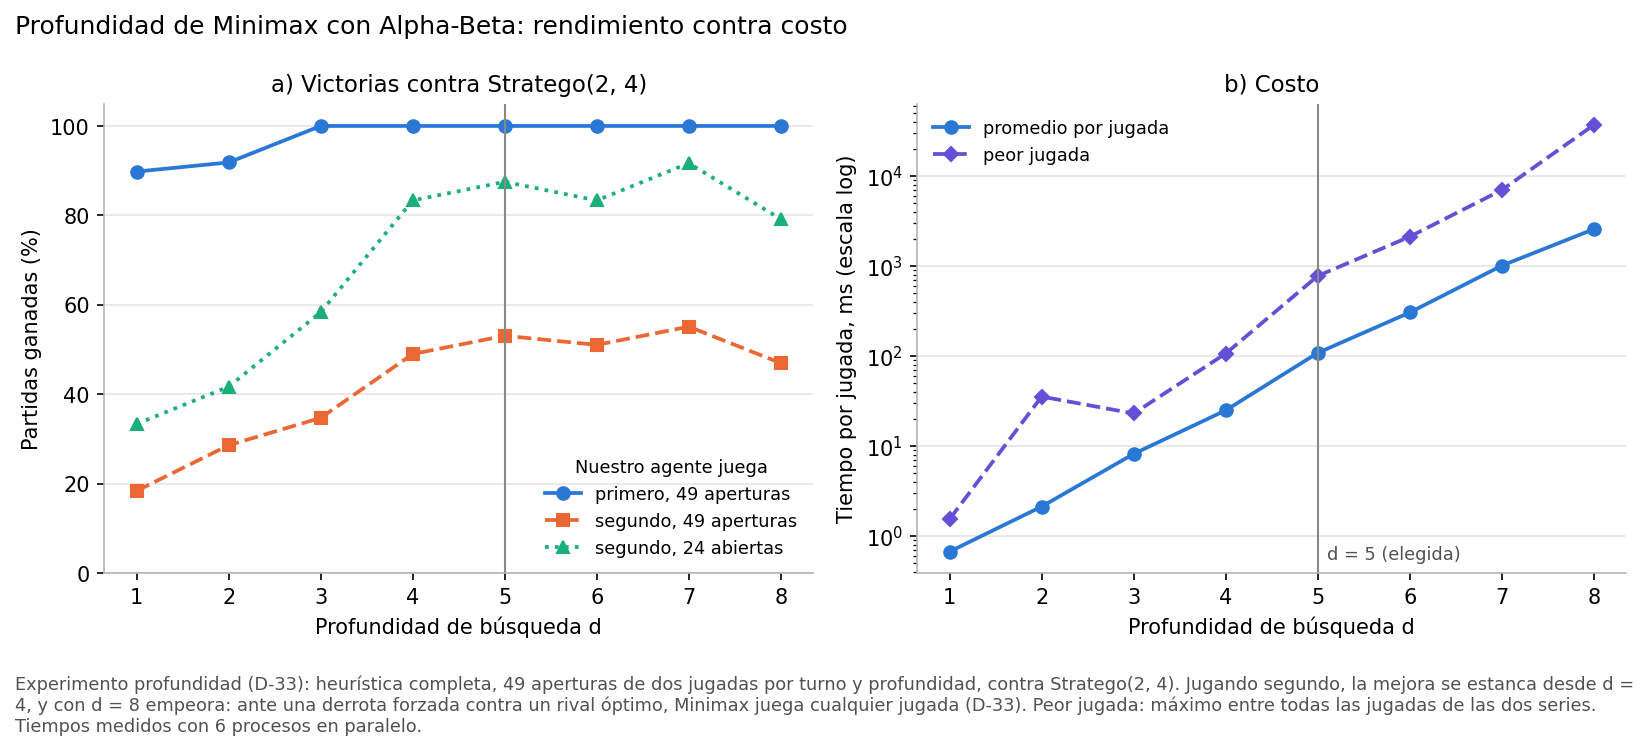

In [8]:
display(Image(filename="figures/C4_profundidad.png"))

## 4. Resumen de enfrentamientos

Victorias, empates y derrotas (V/E/D) sobre las 49 aperturas de dos jugadas (D-29), con la heurística `completa`.

In [9]:
def resumen(experimento):
    with open(RESULTS_DIR / f"summary_{experimento}.csv", newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))

rivales = {"expectimax_random": "Random", "expectimax_stratego": "Stratego(2, 4)", "minimax_vs_expectimax": "Minimax d5"}
filas = ["| Agente | Rival | Juega primero | Juega segundo | ms por jugada |", "|---|---|---|---|---|"]
for experimento, rival in rivales.items():
    rows = resumen(experimento)
    for variante in dict.fromkeys(r["variant"] for r in rows):
        uno, dos = [next(r for r in rows if r["variant"] == variante and r["seat"] == s) for s in ("primero", "segundo")]
        vd = lambda r: f"{r['wins']}/{r['draws']}/{r['losses']}"
        ms = (float(uno["time_per_move_ms"]) + float(dos["time_per_move_ms"])) / 2
        filas.append(f"| {variante} | {rival} | {vd(uno)} | {vd(dos)} | {ms:.0f} |")
display(Markdown("\n".join(filas)))

| Agente | Rival | Juega primero | Juega segundo | ms por jugada |
|---|---|---|---|---|
| minimax_d5 | Random | 49/0/0 | 48/0/1 | 81 |
| expectimax_d5 | Random | 49/0/0 | 47/0/2 | 1179 |
| expectimax_d4 | Random | 49/0/0 | 47/0/2 | 186 |
| minimax_d5 | Stratego(2, 4) | 49/0/0 | 26/0/23 | 103 |
| expectimax_d5 | Stratego(2, 4) | 47/0/2 | 15/0/34 | 1164 |
| expectimax_d4 | Stratego(2, 4) | 49/0/0 | 11/0/38 | 177 |
| minimax_d5 | Minimax d5 | 37/0/12 | 12/0/37 | 104 |
| expectimax_d5 | Minimax d5 | 35/0/14 | 6/0/43 | 1050 |
| expectimax_d4 | Minimax d5 | 29/0/20 | 6/0/43 | 163 |

## 5. Cómo reproducir

Desde `ConnectFour/`, con el entorno activado (o anteponiendo `poetry run`):

```bash
python test_search.py                            # 9 tests: con y sin poda dan el mismo valor y la misma jugada
python experiments.py poda                       # E1: impacto de la poda
python experiments.py heuristicas --split        # E2, separando por clase de apertura
python experiments.py profundidad --split        # E3
python experiments.py expectimax_stratego --split  # E4 (también expectimax_random y minimax_vs_expectimax)
python match.py --rival stratego --openings 2    # una serie del agente final contra Stratego
python plots.py                                  # todas las figuras
```

## Anexo: jugar a mano (celdas de la cátedra)

Con `JUGAR_A_MANO = True`: primero contra el `Stratego(2, 4)` de la cátedra, y después contra nuestro agente final. Las jugadas se ingresan por consola.

In [10]:
from play import play_vs_loaded_agent, play_vs_other_agent

if JUGAR_A_MANO:
    env = ConnectFourBaseEnv(render_mode="human")
    play_vs_loaded_agent(env, agent=InputAgent())
    play_vs_other_agent(env, agent1=InputAgent(), agent2=MinimaxAgent(2))